# Variabilidad del servicio y espera en una cola FCFS
**Cuaderno complementario de la monografía — sin salidas de ejecución guardadas.**

Pregunta: ¿cómo cambia la espera media cuando varía el servicio, manteniendo la tasa de llegada y su media? Esta demostración hipotética compara M/D/1, M/M/1 y M/H₂/1. No representa datos de una organización ni valida un servicio real. No se ha comprobado aquí una ejecución completa en Colab; las tablas y figuras se producirán al ejecutar el código, no son resultados anticipados.

## Uso en Google Colab
1. Abrir https://colab.research.google.com/ y elegir **Archivo → Subir notebook**; seleccionar este `.ipynb`.
2. Usar un entorno Python con CPU y **Entorno de ejecución → Ejecutar todas**. Se requieren NumPy, pandas, Matplotlib, SciPy e IPython (habituales en Colab); no hay instalaciones automáticas. Si falta alguno, detenerse y revisar el entorno.
3. Revisar las pruebas, diagnósticos, tablas y figuras. Guardar una copia con las salidas efectivamente obtenidas; al cambiar parámetros, reiniciar el entorno y ejecutar todo nuevamente.
4. Para entregar al docente, guardar en Drive y usar **Compartir** con permiso de lector según las reglas de la institución. Comprobar el acceso al enlace. Este archivo no publica nada ni crea un enlace automáticamente.

El presupuesto es de **16 800 000 entidades**: puede requerir varios minutos. Solo se conserva un resumen por réplica. No se redacta todavía la sección de resultados de la monografía.

## 1. Modelo y fuentes
Una cola abierta, un servidor, capacidad ilimitada y disciplina FCFS (primero en llegar, primero en ser atendido); sin abandonos, prioridades ni interrupciones. Llegadas Poisson, servicios independientes e idénticamente distribuidos e independientes de las llegadas. Se inicia vacío y se sigue cada entidad hasta completar su servicio.

- [Virtamo: cola M/G/1 y Pollaczek–Khinchine](https://ecs.syr.edu/faculty/fawcett/handouts/CSE681summer/Lecture10/queueNotes/E_lect11.pdf): referencia analítica.
- [Banks y colaboradores: análisis de salidas mediante réplicas](https://dmnicol.web.engr.illinois.edu/ece541/slides/output-analysis.pdf): diapositivas del capítulo 11, sin año ni edición verificados.
- Diseño exacto del trabajo: `monografia/secciones/05_metodologia.tex` y sección 5 de `METODOLOGIA_MONOGRAFIA.md`, entregados con el proyecto. Los tamaños, mezcla y tolerancias son decisiones propias, no recomendaciones numéricas atribuidas a esas fuentes.

La media del servicio es $m=1$ minuto y $\lambda=0{,}8$ entidades/minuto; $\rho=\lambda m=0{,}8<1$. Pollaczek–Khinchine predice $w_\star=\lambda E[S^2]/[2(1-\rho)]$. Son referencias **analíticas**, no observaciones: 2, 4 y 8 minutos para los tres escenarios.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

## 2. Configuración y teoría antes de generar datos
Los identificadores fijos son 0: constante, 1: exponencial y 2: H₂. En H₂ se elige una exponencial de **media** $m/2$ con probabilidad 0,8 o de **media** $3m$ con probabilidad 0,2. Por ello $E[S]=m$, $E[S^2]=4m^2$, $\operatorname{Var}(S)=3m^2$ y $C_s^2=3$. Los otros valores de $C_s^2$ son 0 y 1. NumPy recibe medias en `scale`, no tasas.

Cada realización tiene 140 000 entidades. La ventana principal es `W[20000:120000]` y la alternativa `W[40000:140000]`: 100 000 observaciones cada una y 80 000 compartidas. **No se reinicia la cola** al comenzar ninguna ventana.

In [2]:
from math import isfinite

CONFIG = {'lambda': 0.8, 'm': 1.0, 'replicas': 40, 'entidades': 140000,
          'descarte': 20000, 'alternativo': 40000, 'medicion': 100000,
          'semilla': 2026, 'meta_precision': 0.05, 'tolerancia': 0.02}
ESCENARIOS = {0: 'M/D/1', 1: 'M/M/1', 2: 'M/H₂/1'}

def validar_configuracion(c):
    """Rechazar diseños inválidos antes de generar entradas o archivos."""
    for clave in ('lambda', 'm', 'meta_precision', 'tolerancia'):
        v = c[clave]
        if isinstance(v, bool) or not isinstance(v, (int, float)) or not isfinite(v) or v <= 0:
            raise ValueError(f'{clave}: se requiere un número positivo finito.')
    if c['lambda'] * c['m'] >= 1:
        raise ValueError('Estabilidad: se requiere lambda × m < 1.')
    for clave in ('replicas', 'entidades', 'descarte', 'alternativo', 'medicion', 'semilla'):
        if type(c[clave]) is not int or c[clave] < 0:
            raise ValueError(f'{clave}: se requiere un entero no negativo.')
    if c['replicas'] < 2 or c['medicion'] == 0:
        raise ValueError('Se requieren al menos dos réplicas y medición positiva.')
    if not c['descarte'] < c['alternativo']:
        raise ValueError('El descarte alternativo debe superar al principal.')
    if c['alternativo'] + c['medicion'] > c['entidades']:
        raise ValueError('Las ventanas deben caber en el total de entidades.')

def momentos_teoricos(escenario, c):
    if escenario not in ESCENARIOS:
        raise ValueError('Identificador de escenario desconocido: usar 0, 1 o 2.')
    m = c['m']
    segundo = (1, 2, 4)[escenario] * m**2
    return {'media_servicio_teorica': m, 'segundo_momento': segundo,
            'varianza_servicio_teorica': segundo-m**2,
            'cs2': segundo/m**2-1,
            'espera_teorica': c['lambda']*segundo/(2*(1-c['lambda']*m))}

validar_configuracion(CONFIG)

In [3]:
teoria = pd.DataFrame([{'escenario_id': e, 'modelo': nombre,
                        **momentos_teoricos(e, CONFIG)} for e, nombre in ESCENARIOS.items()])
print('Referencias poblacionales y analíticas; no son resultados simulados.')
display(teoria)

Referencias poblacionales y analíticas; no son resultados simulados.


,escenario_id,modelo,media_servicio_teorica,segundo_momento,varianza_servicio_teorica,cs2,espera_teorica
0,0,M/D/1,1.0,1.0,0.0,0.0,2.0
1,1,M/M/1,1.0,2.0,1.0,1.0,4.0
2,2,M/H₂/1,1.0,4.0,3.0,3.0,8.0


## 3. Generación reproducible de las entradas
Para cada réplica se deriva `SeedSequence([2026, escenario_id, replica_id]).spawn(3)`: flujos separados para llegadas, componentes y servicios. Se reserva el flujo de componentes incluso cuando no se usa. No hay números aleatorios comunes entre escenarios. Solo las dos ventanas dentro de una misma realización están apareadas. La reproducibilidad depende también de las versiones registradas del software.

In [4]:
def generar_entradas(escenario, replica, c):
    validar_configuracion(c)
    if escenario not in ESCENARIOS or type(replica) is not int or not 0 <= replica < c['replicas']:
        raise ValueError('Escenario o índice de réplica inválido.')
    semillas = np.random.SeedSequence([c['semilla'], escenario, replica]).spawn(3)
    llegadas_rng, componente_rng, servicio_rng = [np.random.default_rng(s) for s in semillas]
    n, m = c['entidades'], c['m']
    llegadas = np.cumsum(llegadas_rng.exponential(scale=1/c['lambda'], size=n))
    if escenario == 0:
        servicios = np.full(n, m)
    elif escenario == 1:
        servicios = servicio_rng.exponential(scale=m, size=n)
    else:
        medias = np.where(componente_rng.random(n) < 0.8, m/2, 3*m)
        servicios = servicio_rng.exponential(scale=medias)
    return llegadas, servicios

## 4. Núcleo cronológico FCFS
Con $A_i$ llegada y $S_i$ servicio: $B_i=\max(A_i,D_{i-1})$, $D_i=B_i+S_i$, $W_i=B_i-A_i$ y $T_i=D_i-A_i$, con salida previa inicial cero. El núcleo usa solo la biblioteca estándar; puede probarse independientemente de los paquetes científicos. Rechaza entradas no finitas, negativas o desordenadas y no modifica las entradas. Los índices conservan el orden de llegada, incluso con empates.

In [5]:
from math import isfinite

def simular_fcfs(llegadas, servicios):
    """Devolver listas inicios B, salidas D, esperas W y totales T, en minutos.

    Acepta iterables numéricos de igual longitud, incluso vacíos. El sistema
    comienza vacío; las llegadas deben estar ordenadas y ser no negativas.
    """
    try:
        a = [float(x) for x in llegadas]
        s = [float(x) for x in servicios]
    except (TypeError, ValueError, OverflowError) as error:
        raise ValueError('Llegadas y servicios deben ser números finitos.') from error
    if len(a) != len(s):
        raise ValueError('Llegadas y servicios deben tener igual longitud.')
    if any(not isfinite(x) or x < 0 for x in a + s):
        raise ValueError('Llegadas y servicios deben ser finitos y no negativos.')
    if any(a[i] < a[i-1] for i in range(1, len(a))):
        raise ValueError('Las llegadas deben estar ordenadas cronológicamente.')
    resultado = dict(inicios=[], salidas=[], esperas=[], totales=[])
    previa = 0.0
    for llegada, servicio in zip(a, s):
        inicio = max(llegada, previa)
        salida = inicio + servicio
        if not isfinite(salida):
            raise ValueError('Desbordamiento en los tiempos de salida.')
        resultado['inicios'].append(inicio)
        resultado['salidas'].append(salida)
        resultado['esperas'].append(inicio-llegada)
        resultado['totales'].append(salida-llegada)
        previa = salida
    return resultado

## 5. Verificaciones deterministas antes del experimento
Las pruebas siguientes comprueban casos con y sin espera, invariantes y rechazo de datos inválidos. La referencia analítica 2/4/8 se verifica con una configuración de prueba fija; no exige esos mismos valores si se editan los parámetros del experimento. No prueban por sí solas la ejecución científica completa ni la ausencia de sesgo de inicialización.

In [6]:
r = simular_fcfs([0, 0.5, 2], [1, 1, 1])
assert r == dict(inicios=[0, 1, 2], salidas=[1, 2, 3],
                 esperas=[0, 0.5, 0], totales=[1, 1.5, 1])
r = simular_fcfs([0, 2, 4], [1, 1, 1])
assert r['esperas'] == [0, 0, 0] and r['salidas'] == [1, 3, 5]
a, s = [0, 0, 0.5, 9], [0, 2, 3, 1]
r = simular_fcfs(a, s)
for i in range(len(a)):
    assert r['esperas'][i] >= 0
    assert r['totales'][i] == r['esperas'][i] + s[i]
    assert r['inicios'][i] >= a[i]
    assert i == 0 or r['inicios'][i] >= r['salidas'][i-1]
for a, s in [([1, 0], [1, 1]), ([0], [-1]), ([0], [float('nan')])]:
    try:
        simular_fcfs(a, s)
    except ValueError:
        pass
    else:
        raise AssertionError('Una entrada inválida no fue rechazada.')
config_referencia = {'lambda': 0.8, 'm': 1.0}
for e, esperado in enumerate((2, 4, 8)):
    assert abs(momentos_teoricos(e, config_referencia)['espera_teorica']-esperado) < 1e-12
print('Pruebas deterministas aprobadas; esto no equivale a ejecutar el experimento.')

Pruebas deterministas aprobadas; esto no equivale a ejecutar el experimento.


## 6. Experimento de presupuesto fijo
Una sola simulación por réplica alimenta ambas ventanas. Se agregan inmediatamente sus medias y los momentos empíricos del servicio (sobre las 140 000 entradas, varianza muestral con `ddof=1`). Esos momentos son diagnósticos, no se exige igualdad exacta con la población. No se almacenan todas las entidades de todas las réplicas ni se reintenta para conseguir diagnósticos favorables.

In [7]:
def ejecutar_experimento(c):
    validar_configuracion(c)
    filas = []
    for e, nombre in ESCENARIOS.items():
        for replica in range(c['replicas']):
            a, s = generar_entradas(e, replica, c)
            trayectoria = simular_fcfs(a, s)
            w = np.asarray(trayectoria['esperas'])
            b, bp, n = c['descarte'], c['alternativo'], c['medicion']
            y, yp = float(w[b:b+n].mean()), float(w[bp:bp+n].mean())
            filas.append({'escenario_id': e, 'modelo': nombre, 'replica_id': replica,
                          'Y': y, 'Y_alternativa': yp, 'delta': yp-y,
                          'media_servicio': float(s.mean()),
                          'varianza_servicio': float(s.var(ddof=1)),
                          **c})
            del a, s, trayectoria, w
        print(f'{nombre}: {c["replicas"]} réplicas terminadas.')
    return pd.DataFrame(filas)

metricas = ejecutar_experimento(CONFIG)
print('Métricas agregadas por réplica; primeras filas:')
display(metricas.head())

M/D/1: 40 réplicas terminadas.
M/M/1: 40 réplicas terminadas.
M/H₂/1: 40 réplicas terminadas.
Métricas agregadas por réplica; primeras filas:


,escenario_id,modelo,replica_id,Y,Y_alternativa,delta,media_servicio,varianza_servicio,lambda,m,replicas,entidades,descarte,alternativo,medicion,semilla,meta_precision,tolerancia
0,0,M/D/1,0,2.114368,2.110786,-0.003582,1.0,0.0,0.8,1.0,40,140000,20000,40000,100000,2026,0.05,0.02
1,0,M/D/1,1,1.968379,1.989579,0.021200,1.0,0.0,0.8,1.0,40,140000,20000,40000,100000,2026,0.05,0.02
2,0,M/D/1,2,1.956198,1.960398,0.004200,1.0,0.0,0.8,1.0,40,140000,20000,40000,100000,2026,0.05,0.02
3,0,M/D/1,3,1.962883,1.967946,0.005063,1.0,0.0,0.8,1.0,40,140000,20000,40000,100000,2026,0.05,0.02
4,0,M/D/1,4,2.051431,2.055811,0.004380,1.0,0.0,0.8,1.0,40,140000,20000,40000,100000,2026,0.05,0.02


## 7. Estimaciones e incertidumbre
La unidad estadística es la **media de réplica**, no cada espera correlacionada. Para $K$ medias independientes se usa $\bar Y\pm t_{0.975,K-1}s_Y/\sqrt K$, con varianza muestral (`ddof=1`). El intervalo del 95 % es aproximado; no elimina sesgo común de inicio vacío ni incertidumbre del modelo.

Se informa error relativo **con signo**, $(\bar Y-w_\star)/w_\star$, y la inclusión descriptiva de la referencia en el intervalo. No se exige que toda ejecución contenga la teoría. La meta $h/\bar Y\leq0{,}05$ puede fallar. Para $\Delta=Y'-Y$ se usa otro intervalo entre réplicas; el diagnóstico $|\bar\Delta|+h_\Delta\leq0{,}02w_\star$ puede fallar y **no verifica estacionariedad** aunque sea favorable. Las ventanas comparten 80 000 entidades; no se tratan como independientes.

In [8]:
def resumir(metricas, c):
    filas = []
    for e, grupo in metricas.groupby('escenario_id', sort=True):
        k = len(grupo)
        if k != c['replicas']:
            raise ValueError('Número inesperado de réplicas en el resumen.')
        critico = float(t.ppf(0.975, k-1))
        media = float(grupo['Y'].mean())
        varianza = float(grupo['Y'].var(ddof=1))
        h = critico * (varianza/k)**0.5
        delta = float(grupo['delta'].mean())
        var_delta = float(grupo['delta'].var(ddof=1))
        hd = critico * (var_delta/k)**0.5
        referencia = momentos_teoricos(e, c)['espera_teorica']
        relativo = h/media if media > 0 else float('inf')
        filas.append({'escenario_id': e, 'modelo': ESCENARIOS[e], 'K': k,
                      'media_espera': media, 'varianza_entre_replicas': varianza,
                      'h_95': h, 'limite_inferior': media-h, 'limite_superior': media+h,
                      'espera_teorica': referencia, 'error_relativo_con_signo': (media-referencia)/referencia,
                      'referencia_en_intervalo': bool(media-h <= referencia <= media+h),
                      'semiamplitud_relativa': relativo,
                      'precision_diagnostico': bool(relativo <= c['meta_precision']),
                      'media_delta': delta, 'varianza_delta': var_delta, 'h_delta_95': hd,
                      'tolerancia_minutos': c['tolerancia']*referencia,
                      'inicializacion_diagnostico': bool(abs(delta)+hd <= c['tolerancia']*referencia)})
    return pd.DataFrame(filas)

resumen = resumir(metricas, CONFIG)
display(resumen)
print('Diagnósticos empíricos del servicio frente a momentos poblacionales:')
display(metricas.groupby('escenario_id')[['media_servicio', 'varianza_servicio']].mean().join(
    teoria.set_index('escenario_id')[['media_servicio_teorica', 'varianza_servicio_teorica']]))
print('Interpretar los indicadores como diagnósticos, no como garantía de ausencia de sesgo.')

,escenario_id,modelo,K,media_espera,varianza_entre_replicas,h_95,limite_inferior,limite_superior,espera_teorica,error_relativo_con_signo,referencia_en_intervalo,semiamplitud_relativa,precision_diagnostico,media_delta,varianza_delta,h_delta_95,tolerancia_minutos,inicializacion_diagnostico
0,0,M/D/1,40,2.018183,0.001689,0.013142,2.005041,2.031325,2.0,0.009092,False,0.006512,True,-0.006874,0.000869,0.009427,0.04,True
1,1,M/M/1,40,4.019641,0.018801,0.043852,3.975790,4.063493,4.0,0.004910,True,0.010909,True,0.007267,0.007362,0.027440,0.08,True
2,2,M/H₂/1,40,8.134757,0.173706,0.133293,8.001464,8.268049,8.0,0.016845,False,0.016386,True,-0.045661,0.077280,0.088907,0.16,True


Diagnósticos empíricos del servicio frente a momentos poblacionales:


,media_servicio,varianza_servicio,media_servicio_teorica,varianza_servicio_teorica
escenario_id,,,,
0,1.000000,0.000000,1.0,0.0
1,0.999842,0.999313,1.0,1.0
2,1.000365,3.002724,1.0,3.0


Interpretar los indicadores como diagnósticos, no como garantía de ausencia de sesgo.


## 8. Figuras generadas por esta ejecución
El primer gráfico compara las medias simuladas con su incertidumbre Monte Carlo aproximada del 95 % y la teoría. El segundo compara diferencias apareadas con bandas de tolerancia práctica, no con intervalos de equivalencia demostrada. Ejes en minutos, fondo blanco y marcas distinguibles en escala de grises. Elaboración propia a partir de `metricas` y `resumen`; el código conserva la edición de las figuras. No se interpreta el solapamiento de intervalos marginales como prueba de diferencias entre modelos.

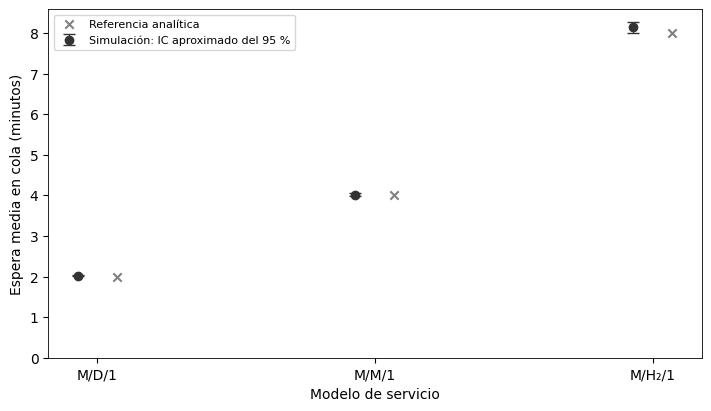

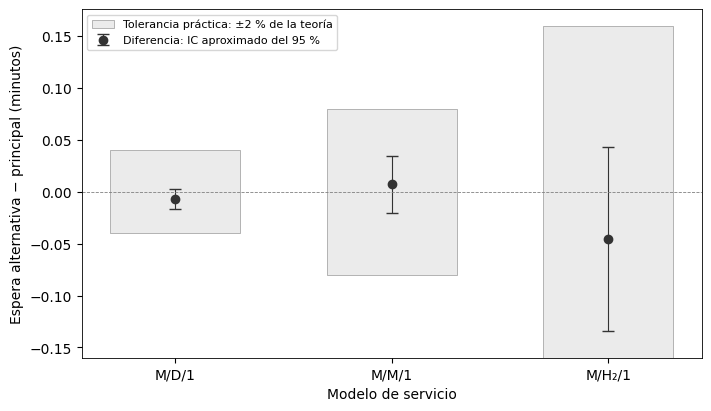

In [9]:
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.linewidth': 0.6, 'font.size': 10})
x = np.arange(len(resumen))
fig_medias, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.errorbar(x-0.07, resumen['media_espera'], yerr=resumen['h_95'], fmt='o',
            color='0.2', capsize=4, linewidth=0.8, label='Simulación: IC aproximado del 95 %')
ax.scatter(x+0.07, resumen['espera_teorica'], marker='x', color='0.5', label='Referencia analítica')
ax.set(xticks=x, xticklabels=resumen['modelo'], xlabel='Modelo de servicio',
       ylabel='Espera media en cola (minutos)')
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.show()

fig_delta, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.bar(x, 2*resumen['tolerancia_minutos'], bottom=-resumen['tolerancia_minutos'],
       width=0.6, color='0.92', edgecolor='0.6', linewidth=0.5,
       label='Tolerancia práctica: ±2 % de la teoría')
ax.errorbar(x, resumen['media_delta'], yerr=resumen['h_delta_95'], fmt='o',
            color='0.2', capsize=4, linewidth=0.8, label='Diferencia: IC aproximado del 95 %')
ax.axhline(0, color='0.5', linewidth=0.6, linestyle='--')
ax.set(xticks=x, xticklabels=resumen['modelo'], xlabel='Modelo de servicio',
       ylabel='Espera alternativa − principal (minutos)')
ax.legend(fontsize=8)
plt.show()

## 9. Lectura crítica pendiente de la ejecución
Antes de redactar resultados, responder con los valores de las tablas: ¿qué precisión se alcanzó en cada escenario?, ¿cuál fue el error con signo frente a la teoría?, ¿qué indica y qué no indica la comparación entre ventanas? Si algún diagnóstico falla, declararlo y conservarlo, sin repetir hasta obtener una salida favorable.

El inicio vacío puede afectar ambas ventanas de modo similar. Los intervalos son aproximaciones entre réplicas, condicionadas a los supuestos y a este presupuesto. La simulación ilustra una comparación analítica; no demuestra una regla general basada solo en varianzas para cualquier disciplina, red o distribución. No extrapolar a servicios reales sin datos. La inspección visual de figuras y la ejecución completa en Colab siguen pendientes hasta realizarlas; este cuaderno no incluye una conclusión experimental preescrita.

## 10. Exportación trazable después de ejecutar y revisar
Esta celda crea `resultados_colas/` en el entorno de ejecución: métricas por réplica con configuración, resumen, configuración CSV, metadatos JSON y dos PNG. No genera PDF. Los archivos corresponden a las variables de esta sesión: ejecutar siempre en orden desde un entorno limpio. El entorno detectado se registra sin asumir que todo Python es Colab. La descarga es una acción manual posterior mediante el panel **Archivos** de Colab; no se publica ni se envían datos a servidores externos desde el código.

In [10]:
from pathlib import Path
import json
import sys
import importlib.util
from importlib.metadata import version
from datetime import datetime, timezone

validar_configuracion(CONFIG)
assert len(metricas) == len(ESCENARIOS)*CONFIG['replicas']
assert len(resumen) == len(ESCENARIOS)
assert np.isfinite(metricas[['Y', 'Y_alternativa', 'delta', 'media_servicio', 'varianza_servicio']]).all().all()
try:
    es_colab = importlib.util.find_spec('google.colab') is not None
except (ModuleNotFoundError, ValueError):
    es_colab = False
metadatos = {'fecha_utc': datetime.now(timezone.utc).isoformat(),
             'execution_environment': 'Google Colab' if es_colab else 'Python fuera de Colab',
             'estado': 'Exportado después de calcular las tablas y figuras en esta sesión',
             'python': sys.version, 'configuracion': CONFIG,
             'escenarios': ESCENARIOS,
             'semillas': 'SeedSequence([semilla, escenario_id, replica_id]).spawn(3)',
             'orden_flujos': ['llegadas', 'componente', 'servicio'],
             'versiones': {p: version(p) for p in ('numpy', 'pandas', 'matplotlib', 'scipy', 'ipython')}}
destino = Path('resultados_colas')
destino.mkdir(exist_ok=True)
metricas.to_csv(destino/'metricas_replicas.csv', index=False)
resumen.to_csv(destino/'resumen.csv', index=False)
pd.DataFrame([CONFIG]).to_csv(destino/'configuracion.csv', index=False)
(destino/'metadatos.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
fig_medias.savefig(destino/'esperas.png', dpi=200, facecolor='white')
fig_delta.savefig(destino/'inicializacion.png', dpi=200, facecolor='white')
print(f'Archivos exportados en {destino}. Guardar también el notebook con sus salidas reales.')

Archivos exportados en resultados_colas. Guardar también el notebook con sus salidas reales.
